In [ ]:
 # Sub-section 1.1: Install specialized biomedical packages
!pip install -q wfdb pydicom pillow scikit-learn seaborn matplotlib pandas numpy

# Sub-section 1.2: Import required standard and third-party libraries
import os
import io
import urllib.request
from collections import Counter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 58.0 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

In [ ]:
# Machine Learning utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Physiological signal processing library
import wfdb

print("Section 1: All libraries successfully imported.")

Section 1: All libraries successfully imported.


In [ ]:
# Sub-section 2.1: Ingestion & Schema Definition
tabular_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak", "slope",
    "ca", "thal", "target"
]

# Read CSV while mapping '?' sentinels to NaN
df_heart = pd.read_csv(tabular_url, names=columns, na_values="?")
print("Sub-section 2.1 Complete: Raw dataset shape:", df_heart.shape)
display(df_heart.head())

Sub-section 2.1 Complete: Raw dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
# Sub-section 2.2: Data Cleaning & Preprocessing
# Impute missing values with column medians
df_heart = df_heart.fillna(df_heart.median(numeric_only=True))

# Binarize target: 0 = Healthy, 1+ = Presence of heart disease
df_heart["target"] = (df_heart["target"] > 0).astype(int)
print(f"Sub-section 2.2 Complete: Class distribution:\n{df_heart['target'].value_counts()}")

Sub-section 2.2 Complete: Class distribution:
target
0    164
1    139
Name: count, dtype: int64


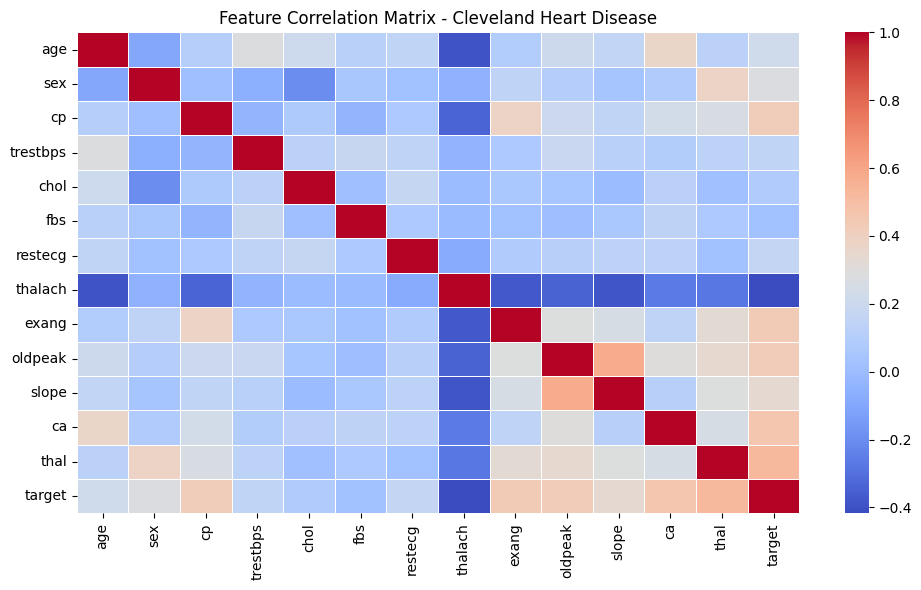

In [ ]:
# Sub-section 2.3: Exploratory Data Analysis (Correlation Heatmap)
plt.figure(figsize=(10, 6))
sns.heatmap(df_heart.corr(), cmap="coolwarm", annot=False, linewidths=0.5)
plt.title("Feature Correlation Matrix - Cleveland Heart Disease")
plt.tight_layout()
plt.show()

In [ ]:

# Sub-section 2.4: Model Training (Logistic Regression Baseline)
X = df_heart.drop("target", axis=1)
y = df_heart["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

clf = LogisticRegression(random_state=42)
clf.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

--- Tabular Model Evaluation ---
Accuracy: 0.8689
ROC-AUC:  0.9513

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



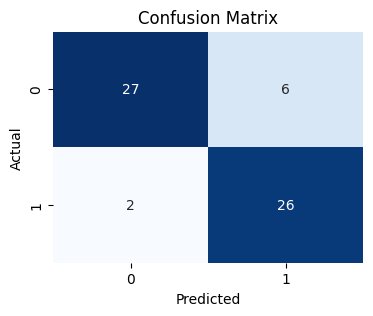

In [ ]:
# Sub-section 2.5: Evaluation & Metrics
y_pred = clf.predict(X_test_scaled)
y_prob = clf.predict_proba(X_test_scaled)[:, 1]

print("--- Tabular Model Evaluation ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_prob):.4f}\n")
print("Classification Report:\n", classification_report(y_test, y_pred))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()